# 一、AdaBoost集成学习

In [2]:
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 自实现模型（models/exp4/）
sys.path.insert(0, ".")
from models.exp4.adaboost import AdaBoostClassifier as MyAdaBoost, DecisionStump
from models.exp4.decision_tree import DecisionTreeClassifier as MyTree


/home/yukari/PycharmProjects/machine_learning/.venv/lib/python3.12/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 13] Permission denied.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


## a.编写Python代码实现AdaBoost模型，选择一个基本分类器作为弱学习器

In [3]:
base_classifier = DecisionTreeClassifier(max_depth=1, random_state=42)

## b.读取数据集，处理缺失值（如有），并将数据集分为训练集和测试集

In [4]:
df = pd.read_csv("data/exp4/Credit_card.csv")
label_df = pd.read_csv("data/exp4/Credit_card_label.csv")

In [5]:
data = pd.merge(df, label_df, on="Ind_ID", how="inner")

In [6]:
X = data.drop(columns=["Ind_ID", "label"])
y = data["label"]

In [7]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numeric_features), ("cat", categorical_transformer, categorical_features)])

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

## c.在训练集上训练AdaBoost模型。在测试集上进行预测，并计算准确率

In [9]:
adaboost = AdaBoostClassifier(estimator=base_classifier, n_estimators=100, learning_rate=1.0, random_state=42)
model = Pipeline(steps=[ ("preprocessor", preprocessor), ("classifier", adaboost)])

In [10]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['GENDER','Car_Owner','Propert_Owner',...,'EMAIL_ID','Type_Occupation', 'Family_Members']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [11]:
y_pred = model.predict(X_test)

In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy：")
print(accuracy)


Accuracy：
0.8817204301075269


## d.打印混淆矩阵，打印分类报告，显示每个类别的精确率、召回率和F1分数

In [13]:
cm = confusion_matrix(y_test, y_pred)

print("\n混淆矩阵：")
print(cm)


混淆矩阵：
[[410   2]
 [ 53   0]]


In [14]:
print("\n分类报告：")

report = classification_report(y_test, y_pred, target_names=["Normal", "Fraud"])

print(report)


分类报告：
              precision    recall  f1-score   support

      Normal       0.89      1.00      0.94       412
       Fraud       0.00      0.00      0.00        53

    accuracy                           0.88       465
   macro avg       0.44      0.50      0.47       465
weighted avg       0.78      0.88      0.83       465



In [15]:
# 自实现的 AdaBoost（以决策树桩为弱学习器）
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

my_adaboost = MyAdaBoost(estimator=DecisionStump(), n_estimators=100,
                         learning_rate=1.0, random_state=42)
my_adaboost.fit(X_train_prep, y_train)
my_pred_ada = my_adaboost.predict(X_test_prep)

ada_comparison = pd.DataFrame({
    "实现方式": ["sklearn 调包", "自实现"],
    "准确率(%)": [accuracy * 100, accuracy_score(y_test, my_pred_ada) * 100],
    "弱学习器数": [len(adaboost.estimators_), my_adaboost.n_estimators_],
})
print("两种 AdaBoost 实现的对比：")
print(ada_comparison.to_string(index=False))
print("\n两种实现的预测一致率：{:.2%}".format((my_pred_ada == y_pred).mean()))


两种 AdaBoost 实现的对比：
      实现方式    准确率(%)  弱学习器数
sklearn 调包 88.172043    100
       自实现 87.956989    100

两种实现的预测一致率：99.78%


## e.绘制混淆均值的热力图

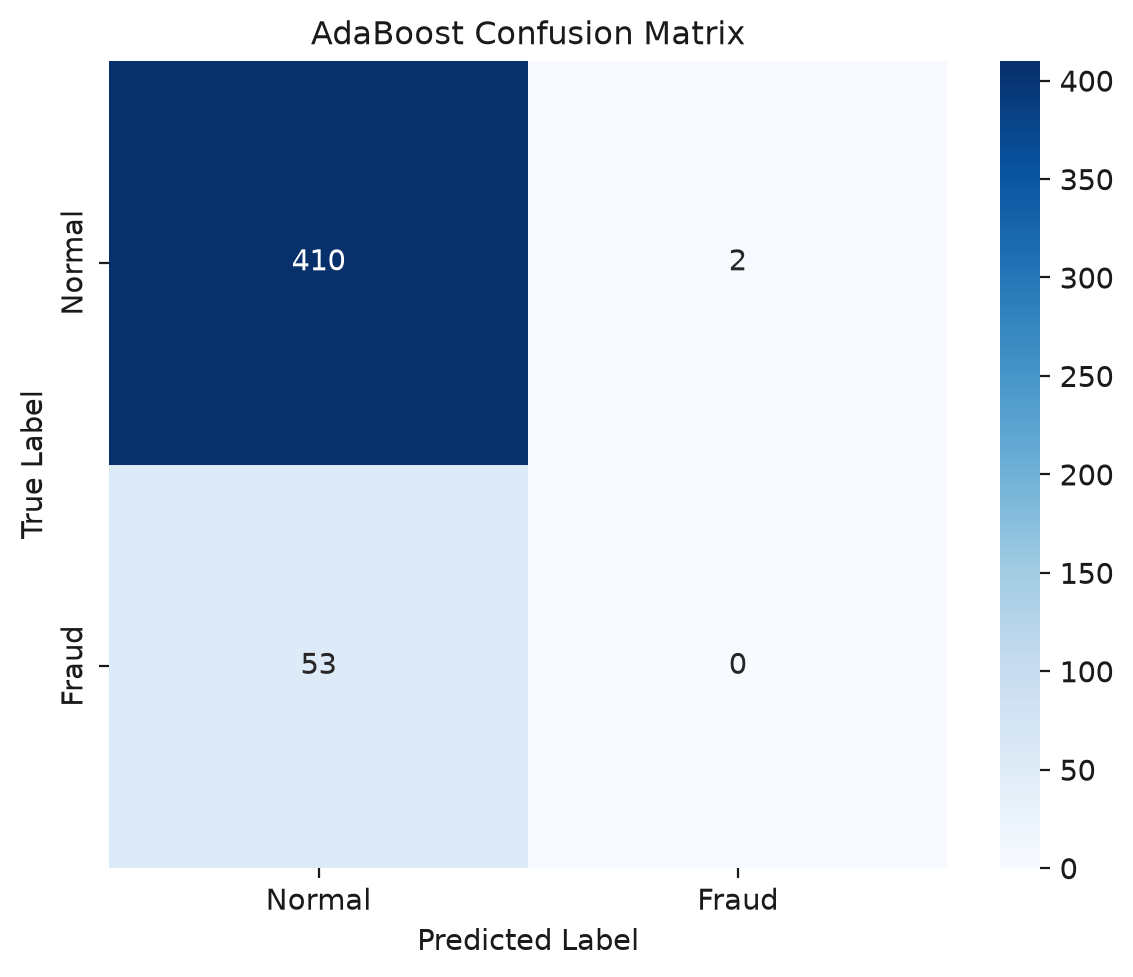

In [16]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("AdaBoost Confusion Matrix")
plt.tight_layout()
plt.show()

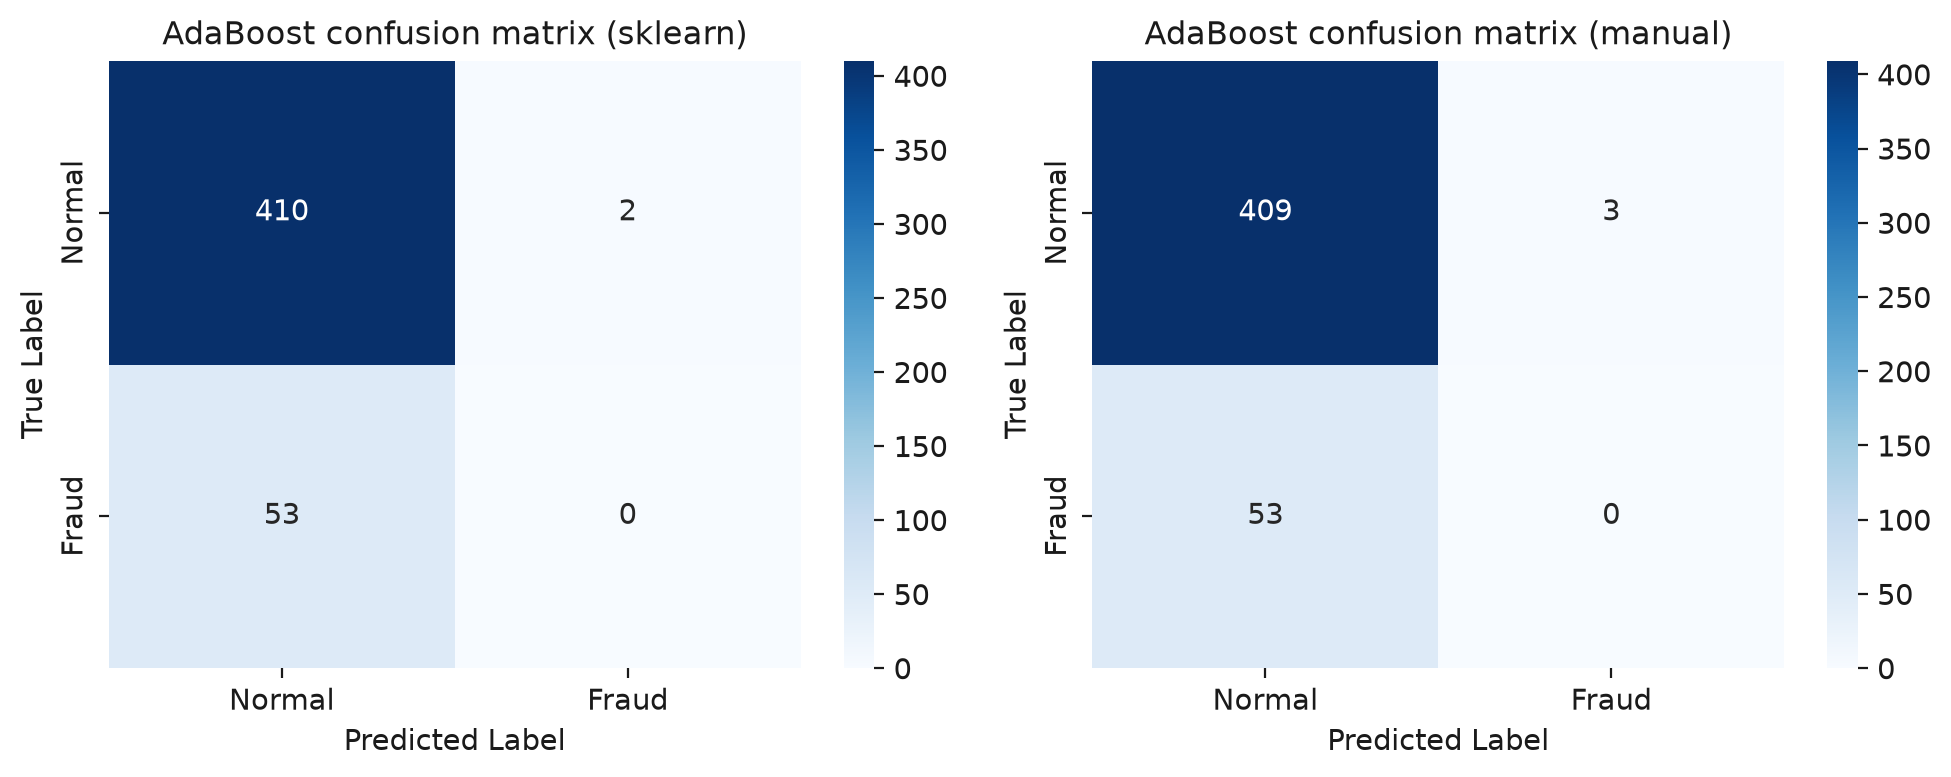

In [17]:
# 两种实现的混淆矩阵对比
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (cm_show, title) in zip(axes, [(cm, "sklearn"),
                                      (confusion_matrix(y_test, my_pred_ada), "manual")]):
    sns.heatmap(cm_show, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_title("AdaBoost confusion matrix ({})".format(title))
plt.tight_layout()
plt.show()


# 二、决策树(非均衡分类问题)

In [18]:
df = pd.read_excel("data/exp4/Florence.xlsx")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Seq#      4000 non-null   int64
 1   Gender    4000 non-null   int64
 2   M         4000 non-null   int64
 3   R         4000 non-null   int64
 4   F         4000 non-null   int64
 5   Florence  4000 non-null   int64
dtypes: int64(6)
memory usage: 187.6 KB


## a.编写Python代码实现决策树模型。(考虑平衡因子)

In [19]:
decision_tree = DecisionTreeClassifier(criterion="entropy", max_depth=5, min_samples_split=10, min_samples_leaf=5, class_weight="balanced", random_state=42)

## b.将数据集分为训练集和测试集，构建决策树模型并进行训练

In [20]:
X = df.drop(columns=["Seq#", "Florence"])
y = df["Florence"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [21]:
decision_tree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are

## c.使用测试集评估模型的性能，包括准确率、混淆矩阵、每个类别的精确率、召回率和F1分数等评估指标

In [22]:
y_pred = decision_tree.predict(X_test)

In [23]:
accuracy = accuracy_score( y_test, y_pred)

print("\n准确率 Accuracy：")
print(accuracy)


准确率 Accuracy：
0.55625


In [24]:
cm = confusion_matrix(y_test, y_pred)

print("\n混淆矩阵：")
print(cm)


混淆矩阵：
[[407 325]
 [ 30  38]]


In [25]:
print("\n分类报告：")

report = classification_report(y_test, y_pred, target_names=["Not Purchased ", "Purchased"])

print(report)


分类报告：
                precision    recall  f1-score   support

Not Purchased        0.93      0.56      0.70       732
     Purchased       0.10      0.56      0.18        68

      accuracy                           0.56       800
     macro avg       0.52      0.56      0.44       800
  weighted avg       0.86      0.56      0.65       800



In [26]:
# 自实现的决策树（熵、深度 5、类别权重平衡）
my_tree = MyTree(criterion="entropy", max_depth=5, min_samples_split=10,
                 min_samples_leaf=5, class_weight="balanced", random_state=42)
my_tree.fit(X_train.values, y_train.values)
my_tree_pred = my_tree.predict(X_test.values)

tree_comparison = pd.DataFrame({
    "实现方式": ["sklearn 调包", "自实现"],
    "准确率(%)": [accuracy * 100, accuracy_score(y_test, my_tree_pred) * 100],
})
print("两种决策树实现的对比：")
print(tree_comparison.to_string(index=False))
print("\n两种实现的预测一致率：{:.2%}".format((my_tree_pred == y_pred).mean()))


两种决策树实现的对比：
      实现方式  准确率(%)
sklearn 调包  55.625
       自实现  56.250

两种实现的预测一致率：99.38%


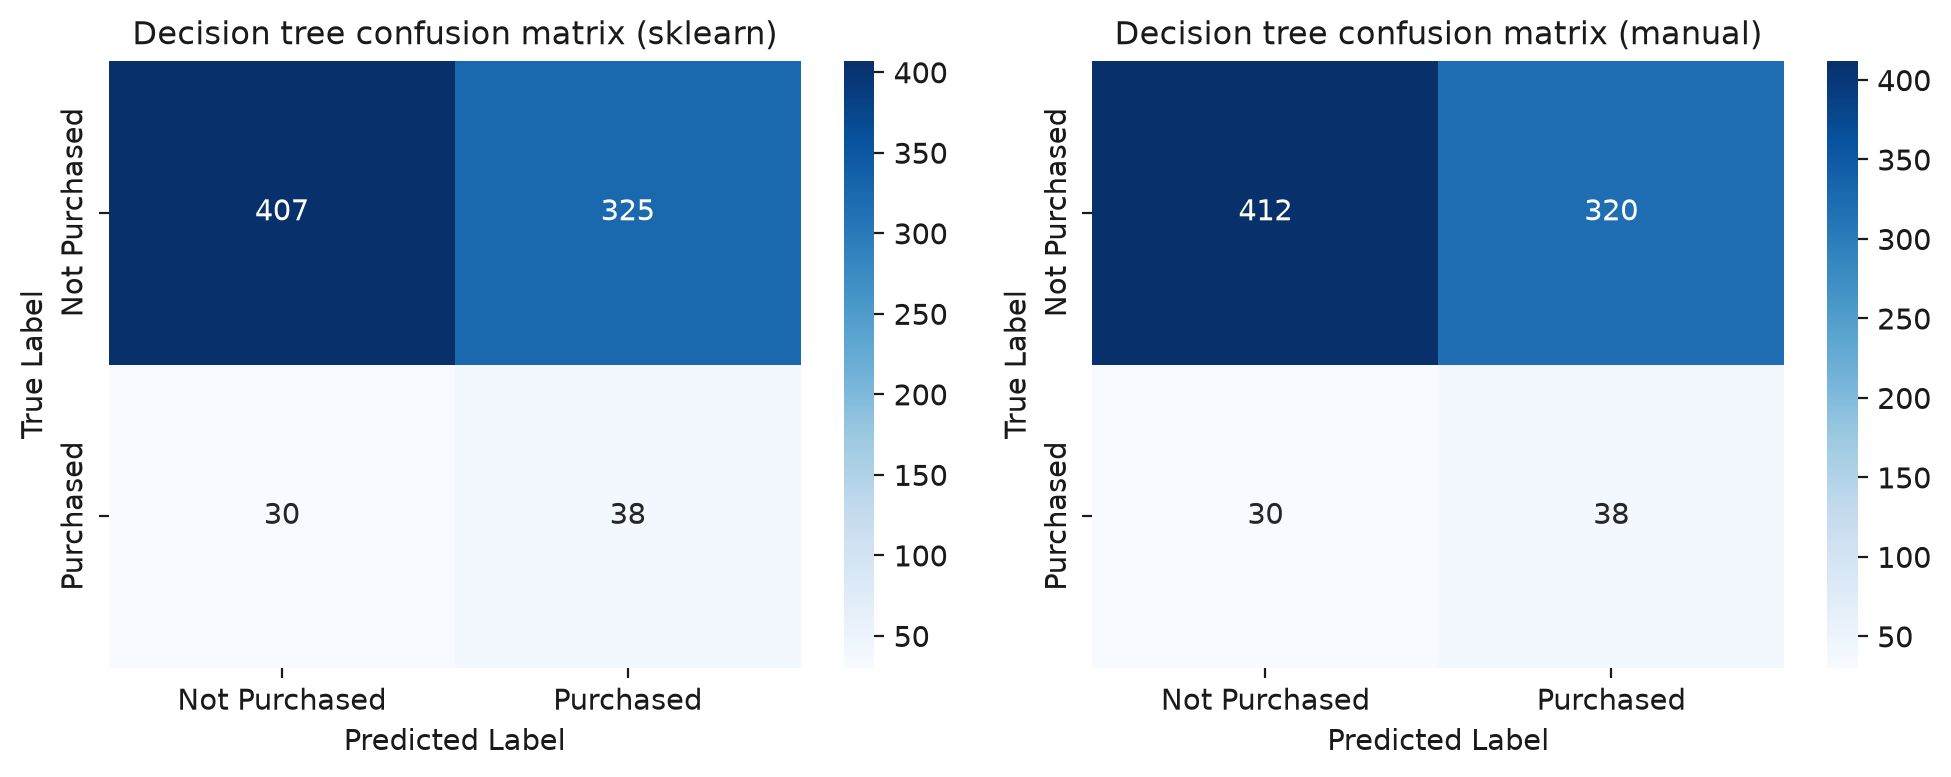

/tmp/ipykernel_35614/445482998.py:24: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_35614/445482998.py:24: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_35614/445482998.py:24: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_35614/445482998.py:24: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_35614/445482998.py:24: UserWarning: Glyph 29616 (\N{CJK UNIFIED IDEOGRAPH-73B0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/yukari/PycharmProjects/machine_learning/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw

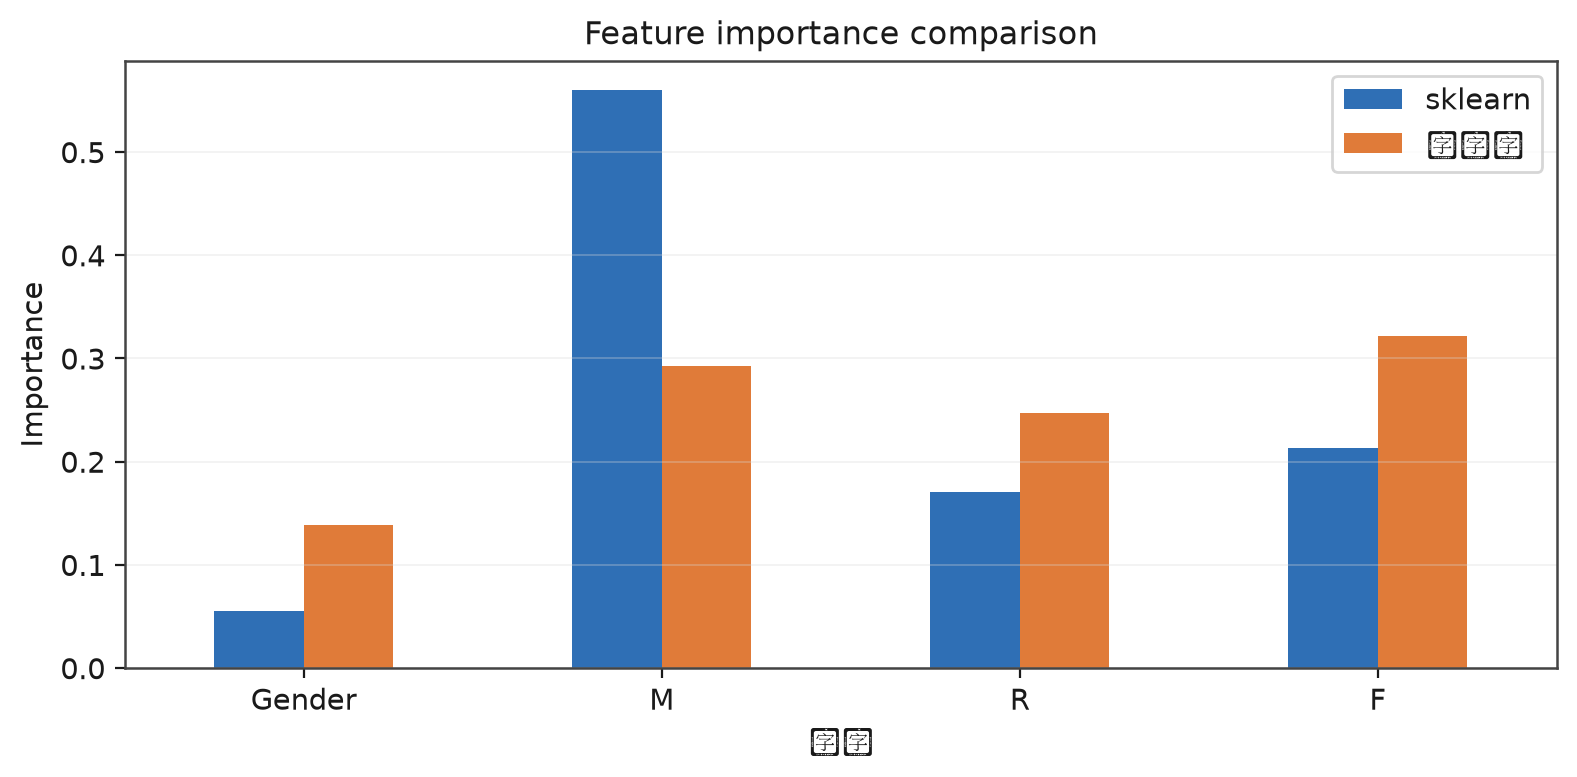

In [27]:
# 两种实现的混淆矩阵与特征重要性对比
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (cm_show, title) in zip(axes, [(cm, "sklearn"),
                                      (confusion_matrix(y_test, my_tree_pred), "manual")]):
    sns.heatmap(cm_show, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Not Purchased", "Purchased"],
                yticklabels=["Not Purchased", "Purchased"])
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_title("Decision tree confusion matrix ({})".format(title))
plt.tight_layout()
plt.show()

importance = pd.DataFrame({
    "特征": X_train.columns,
    "sklearn": decision_tree.feature_importances_,
    "自实现": my_tree.feature_importances_,
}).set_index("特征")
importance.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Importance")
plt.title("Feature importance comparison")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.35)
plt.tight_layout()
plt.show()


## d.随机选取3个特征，重新训练并可视化决策树

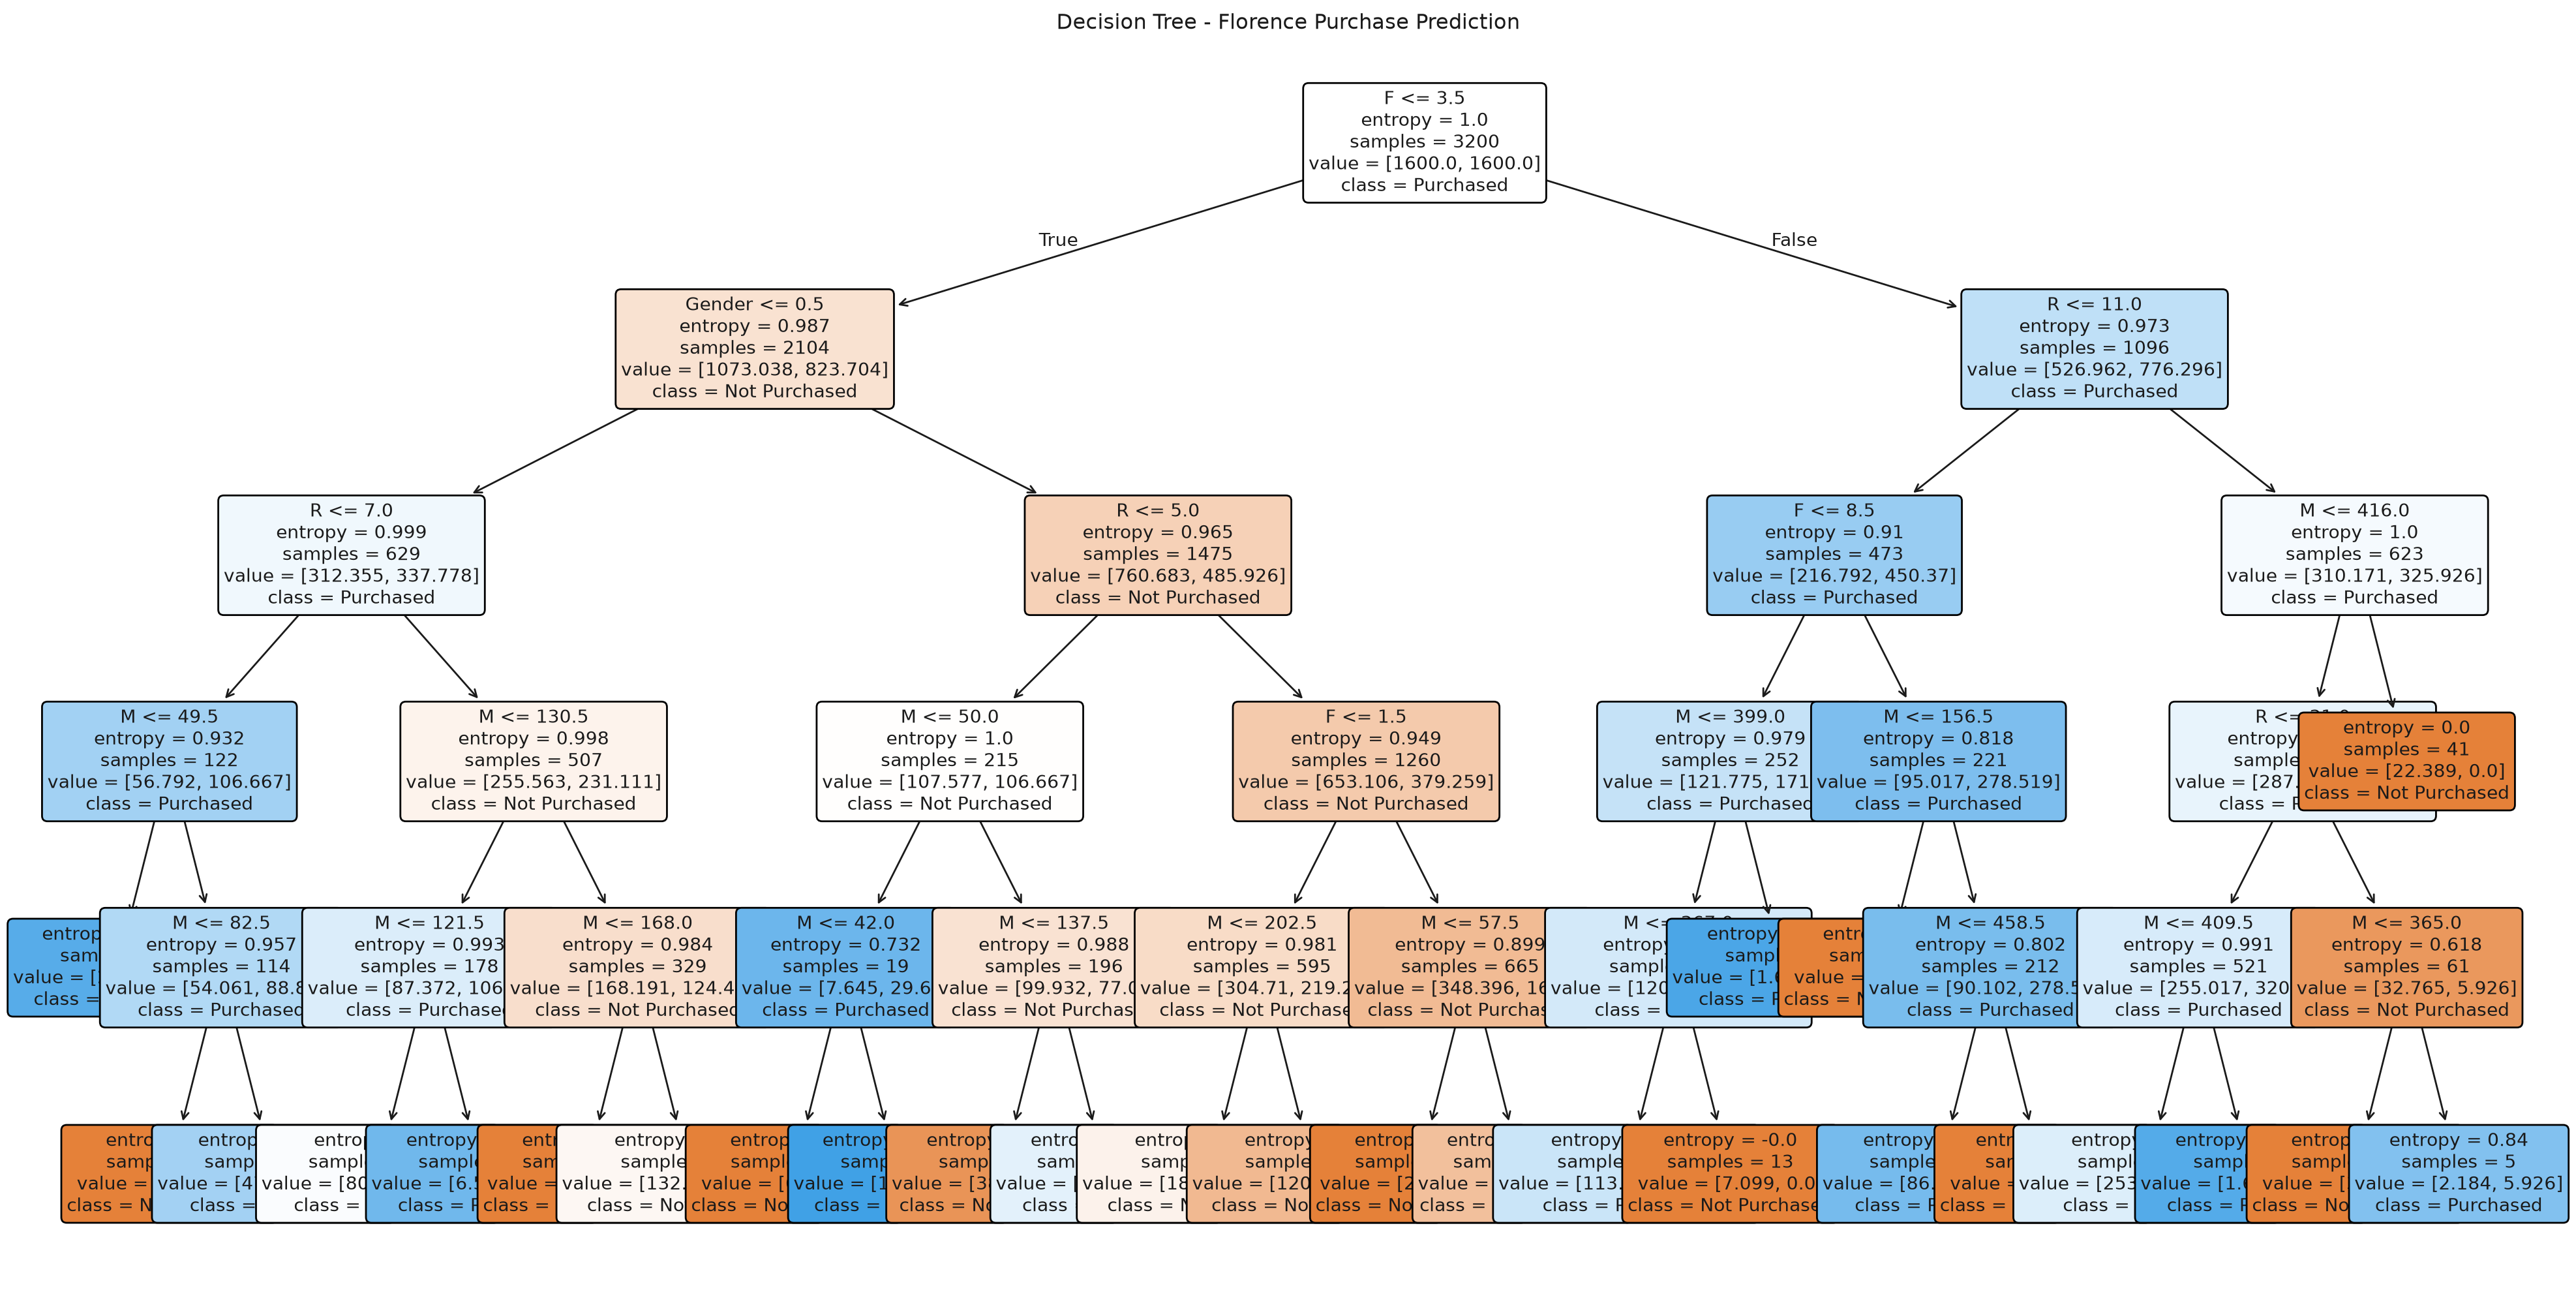

In [28]:
plt.figure(figsize=(20, 10))
plot_tree(decision_tree, feature_names=X.columns, class_names=["Not Purchased", "Purchased"], filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree - Florence Purchase Prediction")
plt.tight_layout()
plt.show()

In [29]:
random.seed(42)

selected_features = random.sample(X.columns.tolist(), 3)
print("\n随机选择的3个特征：")
print(selected_features)


随机选择的3个特征：
['Gender', 'F', 'M']


In [30]:
X_3 = df[selected_features]
y_3 = df["Florence"]

X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(X_3, y_3, test_size=0.2, random_state=42, stratify=y_3)

In [31]:
decision_tree_3 = DecisionTreeClassifier(criterion="entropy", max_depth=5, min_samples_split=10, min_samples_leaf=5, class_weight="balanced", random_state=42)
decision_tree_3.fit(X_train_3, y_train_3)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are

In [32]:
y_pred_3 = decision_tree_3.predict(X_test_3)

In [33]:
accuracy_3 = accuracy_score(y_test_3, y_pred_3)

print("\n==============================")
print("3个特征的决策树模型")
print("==============================")

print("\n选择的特征：")
print(selected_features)

print("\nAccuracy：")
print(accuracy_3)

print("\n混淆矩阵：")
print(confusion_matrix(y_test_3, y_pred_3))

print("\n分类报告：")
print(classification_report(y_test_3, y_pred_3, target_names=["Not Purchased", "Purchased"]))


3个特征的决策树模型

选择的特征：
['Gender', 'F', 'M']

Accuracy：
0.5425

混淆矩阵：
[[399 333]
 [ 33  35]]

分类报告：
               precision    recall  f1-score   support

Not Purchased       0.92      0.55      0.69       732
    Purchased       0.10      0.51      0.16        68

     accuracy                           0.54       800
    macro avg       0.51      0.53      0.42       800
 weighted avg       0.85      0.54      0.64       800



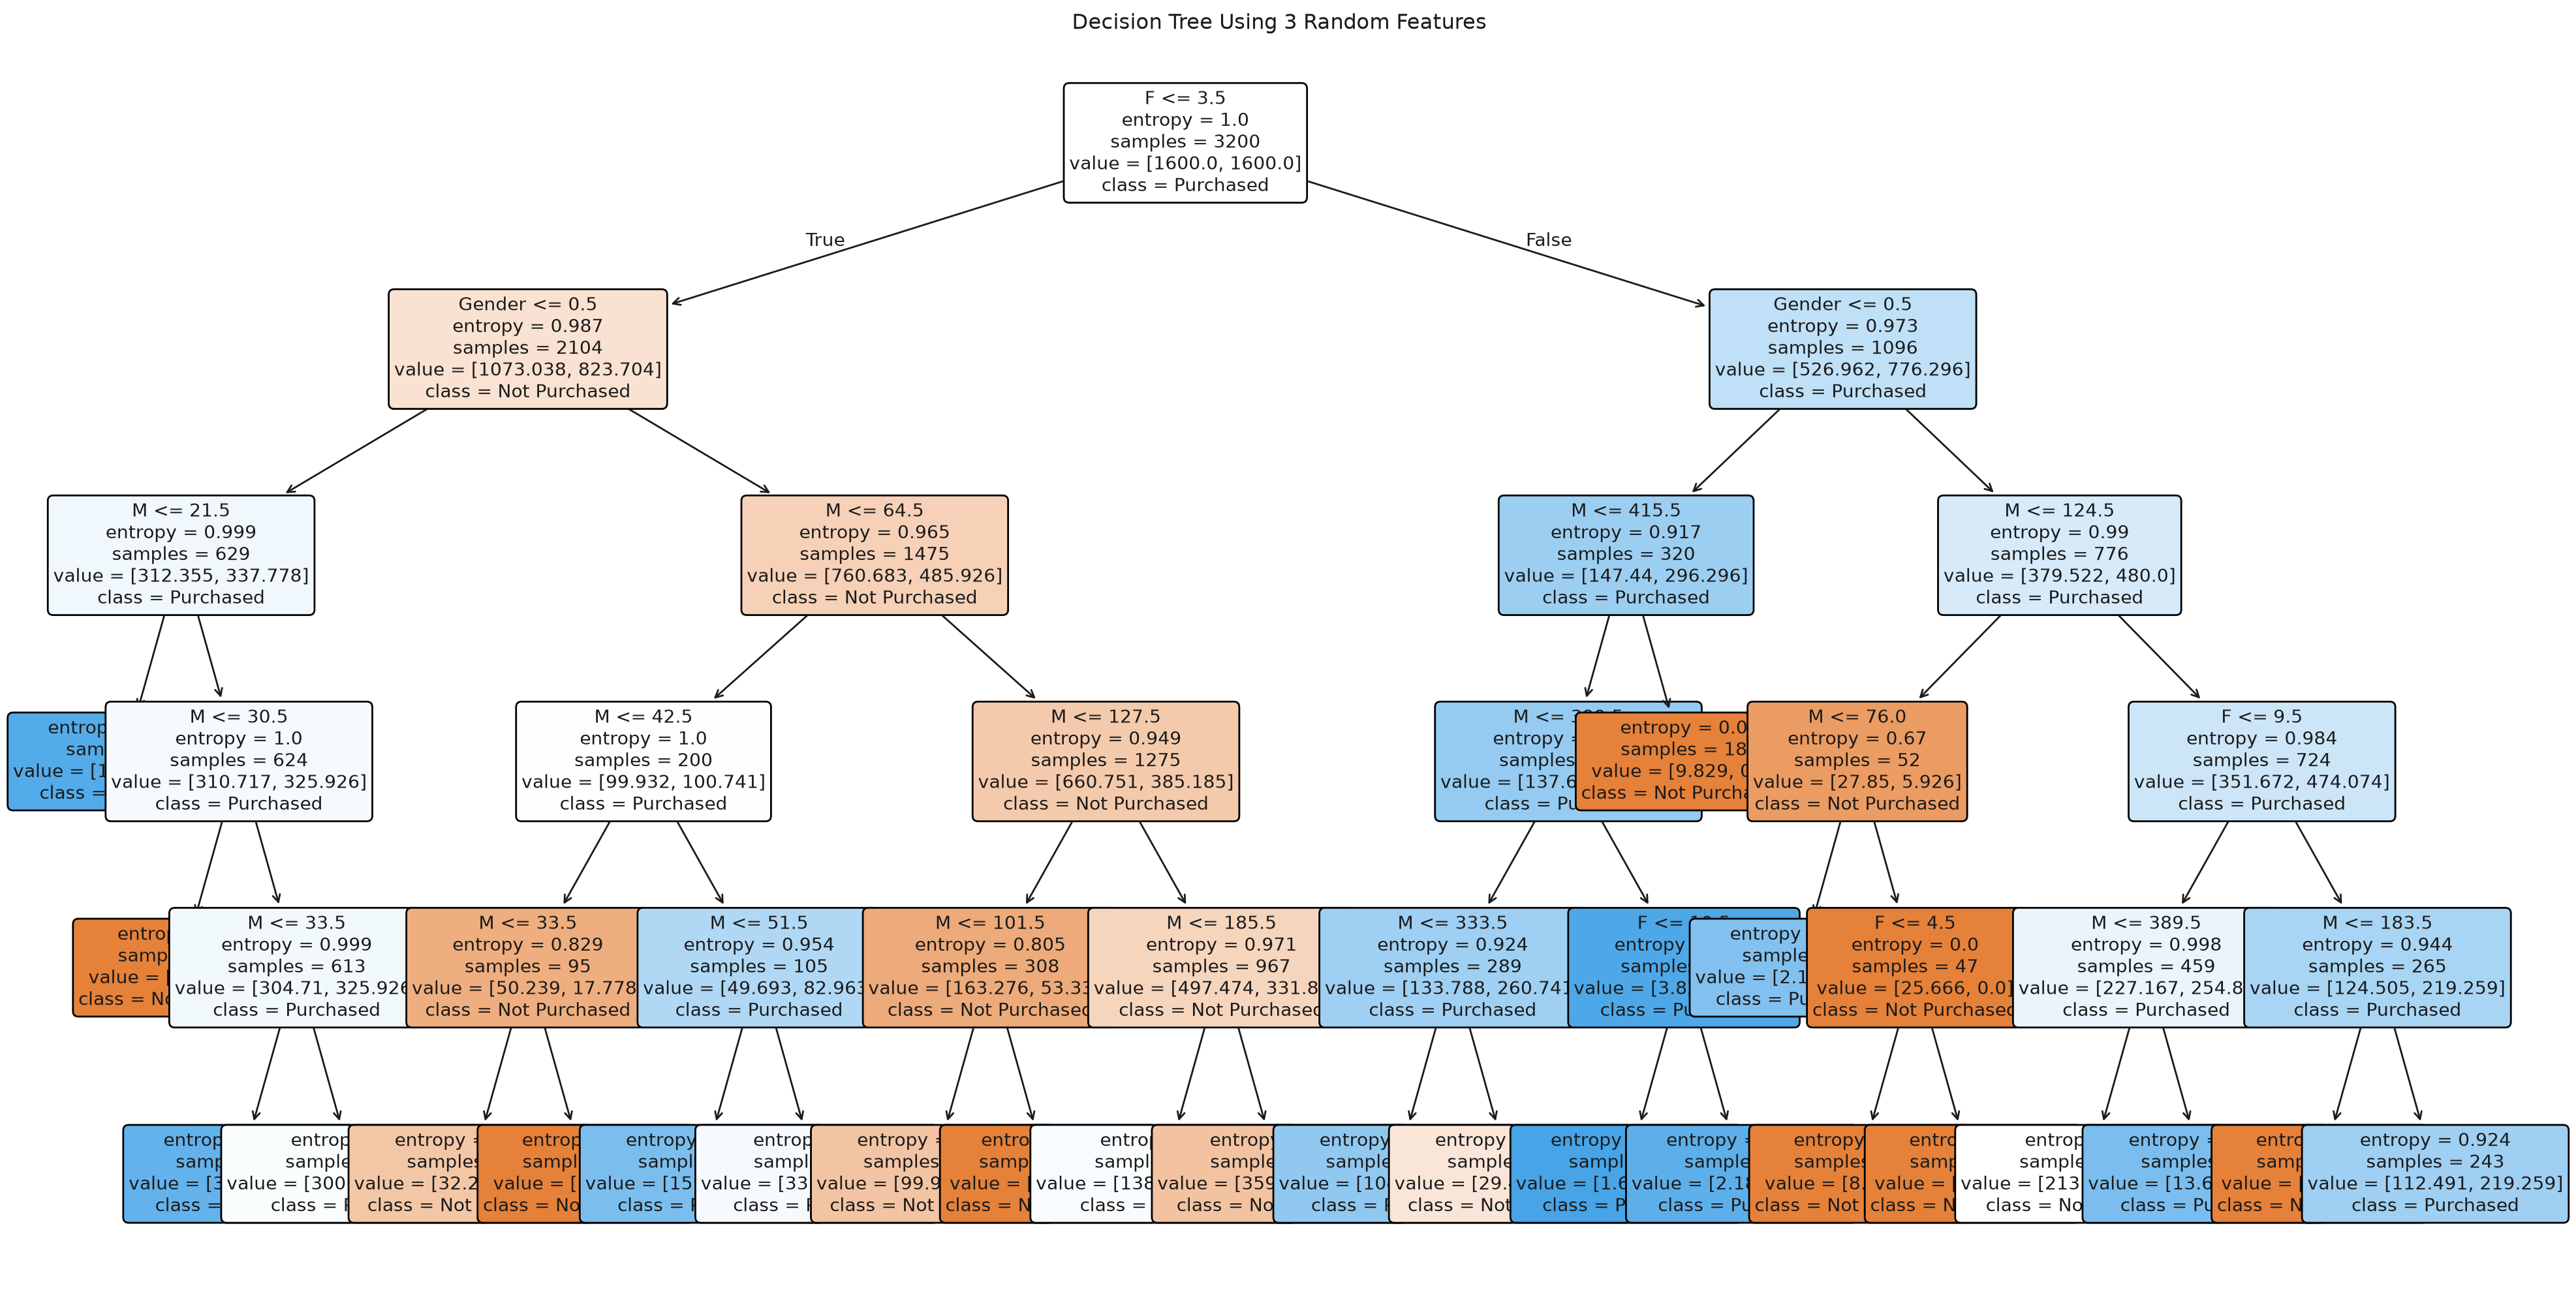

In [34]:
plt.figure(figsize=(20, 10))
plot_tree(decision_tree_3, feature_names=selected_features, class_names=["Not Purchased", "Purchased"], filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree Using 3 Random Features")
plt.tight_layout()
plt.show()